# Bean Leaf Doctor: classifying bean leaf diseases from photos

**Author:** Sheila Kaliza Milena Rwakunda, Machine Learning Pipeline summative

**Mission link (Ascend Rwanda).** My Intro to ML project looked at what drives economic opportunity, using census income data. Most Rwandan households earn their living from small farms, and beans are one of the country's main staple crops. Two leaf diseases, **bean rust** and **angular leaf spot**, can destroy a large part of a harvest. If a farmer can photograph a leaf and find out early whether it is sick, they can act before the loss spreads. That protects household income, which is the economic opportunity theme of my earlier project.

**Task.** Image classification with 3 classes: `angular_leaf_spot`, `bean_rust`, `healthy`.

**Dataset.** The *iBean* dataset by the Makerere University AI Lab (Uganda): photos of bean leaves taken with phones on real East African farms and labelled by agricultural experts. It comes already split into train (1,034), validation (133) and test (128) images. License: MIT.

**Plan of this notebook**
1. Data acquisition
2. Exploring the data (visualisations of 3 features)
3. Preprocessing
4. A simple baseline model (no optimisation)
5. The optimised model: transfer learning with MobileNetV2 + regularisation + early stopping + fine-tuning
6. Evaluation with accuracy, loss, precision, recall, F1, ROC-AUC and a confusion matrix
7. Saving the model, prediction function and retraining function

## 0. Setup
Run this notebook in **Google Colab** with a GPU: *Runtime → Change runtime type → T4 GPU*. Then *Runtime → Run all*.

In [1]:
import os, json, random, shutil, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from PIL import Image
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, log_loss,
                             classification_report, confusion_matrix, roc_auc_score)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
IMG_SIZE = (224, 224)
BATCH = 32
CLASS_NAMES = ["angular_leaf_spot", "bean_rust", "healthy"]
PROJECT = Path("bean-mlop")             # everything we produce goes here
DATA_DIR, MODELS_DIR = PROJECT / "data", PROJECT / "models"
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Data acquisition
We download the dataset with `tensorflow_datasets` (a library that fetches well-known public datasets). If that fails, we fall back to the copy on Hugging Face.
Then we save every picture as a JPEG file into folders named after its class, the layout the rest of the project (API, retraining) expects:
```
data/train/<class>/*.jpg
data/test/<class>/*.jpg
```
We resize to 224×224 when saving so the files stay small enough for GitHub.

In [2]:
def load_splits():
    try:
        import tensorflow_datasets as tfds
        splits = tfds.load("beans", split=["train", "validation", "test"], as_supervised=True)
        names = tfds.builder("beans").info.features["label"].names
        out = []
        for ds in splits:
            out.append([(img.numpy(), names[int(lbl)]) for img, lbl in ds])
        return out
    except Exception as e:
        print("TFDS failed, using Hugging Face instead:", e)
        !pip -q install datasets
        from datasets import load_dataset
        hf = load_dataset("AI-Lab-Makerere/beans")
        names = hf["train"].features["labels"].names
        return [[(np.array(r["image"].convert("RGB")), names[r["labels"]]) for r in hf[s]]
                for s in ["train", "validation", "test"]]

train_raw, val_raw, test_raw = load_splits()
print(len(train_raw), "train |", len(val_raw), "validation |", len(test_raw), "test")
print("Original image size:", train_raw[0][0].shape)

TFDS failed, using Hugging Face instead: No module named 'importlib_resources'


README.md:   0%|          | 0.00/4.95k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  144MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.5MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/1034 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/133 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/128 [00:00<?, ? examples/s]

1034 train | 133 validation | 128 test
Original image size: (500, 500, 3)


In [3]:
def save_split(items, folder):
    folder = Path(folder)
    if folder.exists(): shutil.rmtree(folder)
    for i, (arr, label) in enumerate(items):
        p = folder / label / f"{label}_{i:04d}.jpg"
        p.parent.mkdir(parents=True, exist_ok=True)
        Image.fromarray(arr).convert("RGB").resize(IMG_SIZE, Image.BILINEAR).save(p, quality=92)

save_split(train_raw, DATA_DIR / "train")
save_split(test_raw, DATA_DIR / "test")
save_split(val_raw, PROJECT / "val_tmp")     # validation is only used inside this notebook
for split in ["train", "test"]:
    print(split, {c: len(list((DATA_DIR / split / c).glob('*.jpg'))) for c in CLASS_NAMES})

train {'angular_leaf_spot': 345, 'bean_rust': 348, 'healthy': 341}
test {'angular_leaf_spot': 43, 'bean_rust': 43, 'healthy': 42}


## 2. Exploring the data

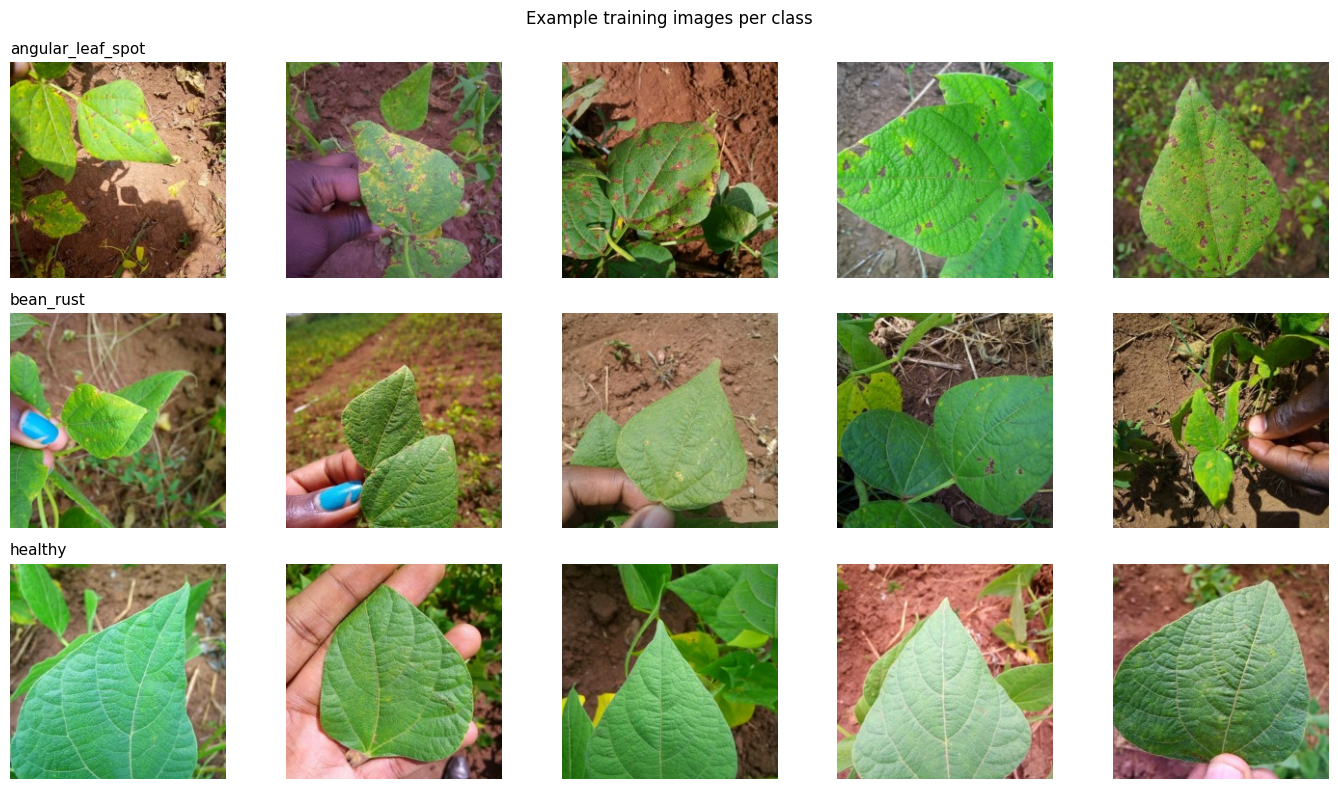

In [4]:
fig, axes = plt.subplots(3, 5, figsize=(14, 8))
for row, cls in enumerate(CLASS_NAMES):
    files = sorted((DATA_DIR / "train" / cls).glob("*.jpg"))[:5]
    for col, f in enumerate(files):
        axes[row, col].imshow(Image.open(f)); axes[row, col].axis("off")
        axes[row, col].set_title(cls if col == 0 else "", loc="left", fontsize=11)
plt.suptitle("Example training images per class"); plt.tight_layout(); plt.show()

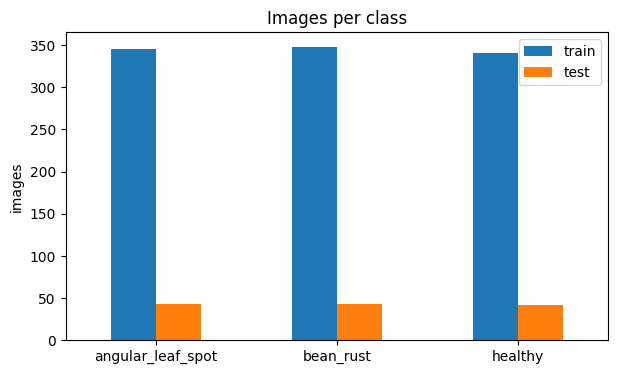

,train,test
angular_leaf_spot,345,43
bean_rust,348,43
healthy,341,42


In [5]:
counts = pd.DataFrame({split: [len(list((DATA_DIR / split / c).glob('*.jpg'))) for c in CLASS_NAMES]
                       for split in ["train", "test"]}, index=CLASS_NAMES)
counts.plot.bar(figsize=(7, 4), rot=0, title="Images per class"); plt.ylabel("images"); plt.show()
counts

**Class balance.** The three classes have almost the same number of pictures, so we do not need class weights, and accuracy is a fair headline metric. We still report precision, recall and F1 per class.

### Three features of the pictures
A photo is just numbers (red, green and blue values for every pixel). To understand the data, I measured three simple features for each image:

1. **Greenness**: the share of pixels where green clearly dominates. Healthy leaf tissue is green.
2. **Lesion-colour share**: the share of brown, yellow or rust-coloured pixels. Disease spots have these colours.
3. **Brightness**: the average pixel value, which mostly reflects lighting when the photo was taken.

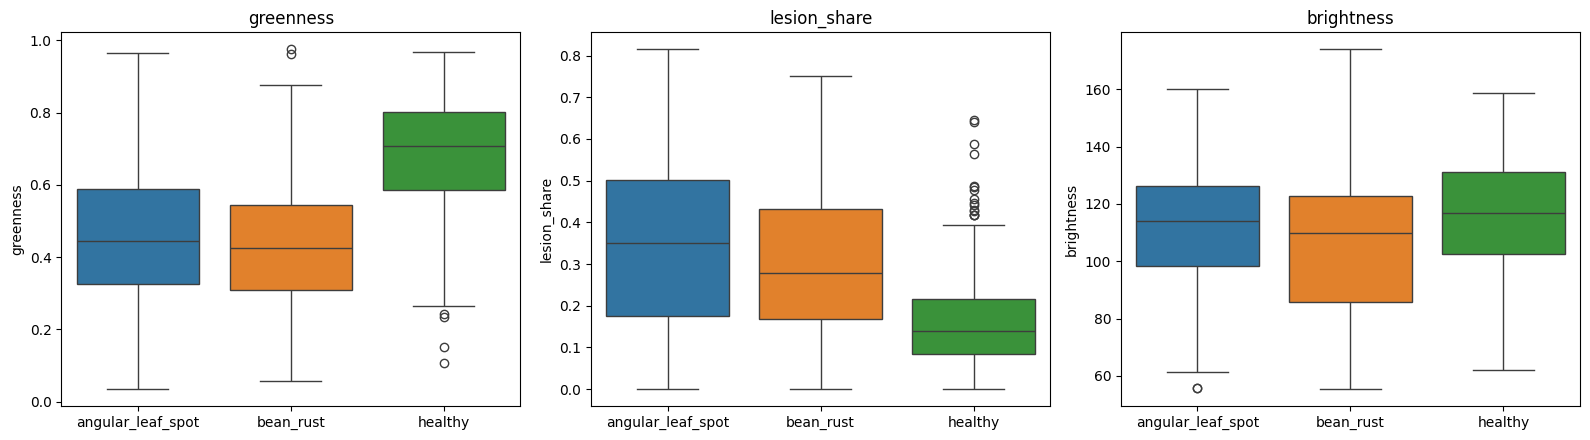

,brightness,greenness,lesion_share
class,,,
angular_leaf_spot,112.629997,0.46,0.347
bean_rust,106.158997,0.44,0.304
healthy,116.809998,0.69,0.162


In [6]:
def colour_features(img):
    arr = np.asarray(img.convert("RGB").resize((128, 128)), dtype=np.float32)
    r, g, b = arr[..., 0], arr[..., 1], arr[..., 2]
    green = (g > r * 1.05) & (g > b * 1.05)
    lesion = (r > 90) & (r >= g * 0.95) & (b < g) & (b < r * 0.75)
    return {"brightness": arr.mean(), "greenness": green.mean(), "lesion_share": lesion.mean()}

rows = []
for cls in CLASS_NAMES:
    for f in (DATA_DIR / "train" / cls).glob("*.jpg"):
        rows.append({"class": cls, **colour_features(Image.open(f))})
feat = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ["greenness", "lesion_share", "brightness"]):
    sns.boxplot(data=feat, x="class", y=col, ax=ax, hue="class", legend=False)
    ax.set_title(col); ax.set_xlabel("")
plt.tight_layout(); plt.show()
feat.groupby("class").mean().round(3)

**What story do the features tell?**

| class | greenness | lesion-colour share | brightness |
|---|---|---|---|
| angular leaf spot | 0.46 | 0.35 | 113 |
| bean rust | 0.44 | 0.30 | 106 |
| healthy | **0.69** | **0.16** | 117 |

- **Greenness**: healthy leaves are clearly the greenest (69% green pixels against about 45% for sick leaves). Both diseases destroy green leaf tissue, so a sick leaf loses about a third of its green.
- **Lesion-colour share**: sick leaves have about twice as many brown, yellow or rust-coloured pixels as healthy ones (30 to 35% against 16%). Angular leaf spot scores slightly higher than bean rust because its patches are large, while rust makes many tiny pustules. Healthy leaves still score above zero because of soil, shadows and dry edges in the background.
- **Brightness**: the three classes are close (106 to 117 out of 255) and the boxes overlap a lot. Brightness mostly reflects sunlight and the phone camera, not the disease, so the model should *not* rely on it. That is why we add brightness and contrast augmentation.

**The story:** colour separates *healthy vs sick* quite well, but the two diseases look almost the same by colour alone (0.46 vs 0.44 greenness, 0.35 vs 0.30 lesion share). Telling them apart needs the *shape and texture* of the spots, which is exactly what a convolutional neural network learns. We expect most model mistakes to be between the two diseases.

## 3. Preprocessing
Steps applied to every image:
1. **Resize** to 224×224 (done when saving).
2. **Convert** to an array of numbers, shape (224, 224, 3).
3. **Scale** pixel values from 0–255 to −1…1. This is what MobileNetV2 expects. It is done *inside* the model (a `Rescaling` layer), so the API cannot forget it.
4. **Data augmentation** (training only): random flips, rotations, zoom and contrast. These create new variations of each photo so the model does not memorise the training set.
5. **Batching and prefetching** with the `tf.data` API for speed.

Found 1034 files belonging to 3 classes.
Found 133 files belonging to 3 classes.
Found 128 files belonging to 3 classes.


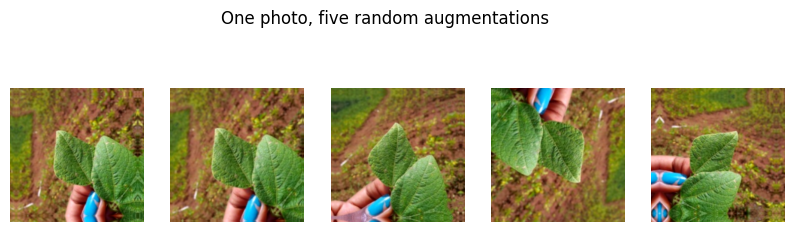

In [7]:
def make_ds(folder, shuffle):
    return keras.utils.image_dataset_from_directory(
        folder, labels="inferred", label_mode="int", class_names=CLASS_NAMES,
        image_size=IMG_SIZE, batch_size=BATCH, shuffle=shuffle, seed=SEED)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = make_ds(DATA_DIR / "train", True).prefetch(AUTOTUNE)
val_ds   = make_ds(PROJECT / "val_tmp", False).prefetch(AUTOTUNE)
test_ds  = make_ds(DATA_DIR / "test", False).prefetch(AUTOTUNE)

augment = keras.Sequential([
    keras.layers.RandomFlip("horizontal_and_vertical"),
    keras.layers.RandomRotation(0.15),
    keras.layers.RandomZoom(0.15),
    keras.layers.RandomContrast(0.15),
], name="augmentation")

images, _ = next(iter(train_ds))
plt.figure(figsize=(10, 3))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(augment(images[:1], training=True)[0].numpy().astype("uint8")); plt.axis("off")
plt.suptitle("One photo, five random augmentations"); plt.show()

## 4. Baseline: a small CNN trained from scratch (no optimisation)
A plain convolutional network, default settings, no augmentation, no regularisation and no early stopping. It shows what we get *without* the optimisation techniques.

In [8]:
baseline = keras.Sequential([
    keras.Input(shape=(*IMG_SIZE, 3)),
    keras.layers.Rescaling(1/255.),
    keras.layers.Conv2D(16, 3, activation="relu"), keras.layers.MaxPooling2D(),
    keras.layers.Conv2D(32, 3, activation="relu"), keras.layers.MaxPooling2D(),
    keras.layers.Conv2D(64, 3, activation="relu"), keras.layers.MaxPooling2D(),
    keras.layers.Flatten(),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(3, activation="softmax"),
], name="baseline_cnn")
baseline.compile(optimizer="sgd", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist_base = baseline.fit(train_ds, validation_data=val_ds, epochs=15)

Epoch 1/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 23s 355ms/step - accuracy: 0.4197 - loss: 1.0765 - val_accuracy: 0.5263 - val_loss: 1.0441
Epoch 2/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.4932 - loss: 1.0191 - val_accuracy: 0.3684 - val_loss: 1.0249
Epoch 3/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.5338 - loss: 0.9723 - val_accuracy: 0.3684 - val_loss: 1.1801
Epoch 4/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.5638 - loss: 0.9290 - val_accuracy: 0.3759 - val_loss: 1.2524
Epoch 5/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.5716 - loss: 0.9229 - val_accuracy: 0.4361 - val_loss: 1.1148
Epoch 6/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.6219 - loss: 0.8416 - val_accuracy: 0.5263 - val_loss: 0.9338
Epoch 7/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.6509 - loss: 0.7905 - val_accuracy: 0.6165 - val_loss: 0.8233
Epoch 8/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.6615 - loss: 0.7590 - val_accuracy: 0.5489 -

## 5. Optimised model: transfer learning with MobileNetV2
**Transfer learning** means starting from a network that has already learned to see edges, textures and shapes from 1.4 million ImageNet photos, and only teaching it the last step (our 3 classes).

Optimisation techniques used (the rubric lists these):
| Technique | Where |
|---|---|
| **Pre-trained model** | MobileNetV2 with ImageNet weights |
| **Optimizer** | Adam (learning rate 1e-3, then 1e-5 for fine-tuning) |
| **Regularisation** | Dropout 0.3 + L2 weight penalty on the output layer + data augmentation |
| **Early stopping** | stops when validation loss stops improving and restores the best weights |
| **Learning-rate schedule** | ReduceLROnPlateau |
| **Hyperparameter tuning** | small search over dropout rate (below) |

In [9]:
def build_model(dropout=0.3, l2=1e-4, lr=1e-3):
    base = keras.applications.MobileNetV2(input_shape=(*IMG_SIZE, 3), include_top=False, weights="imagenet")
    base.trainable = False
    inputs = keras.Input(shape=(*IMG_SIZE, 3), name="image")
    x = augment(inputs)
    x = keras.layers.Rescaling(1/127.5, offset=-1, name="scale_to_minus1_1")(x)
    x = base(x, training=False)
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dropout(dropout)(x)
    outputs = keras.layers.Dense(3, activation="softmax",
                                 kernel_regularizer=keras.regularizers.l2(l2), name="prediction")(x)
    model = keras.Model(inputs, outputs, name="bean_leaf_mobilenetv2")
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def callbacks(patience=4):
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7)]

### 5a. Small hyperparameter search: which dropout rate works best?

In [10]:
search = []
for d in [0.2, 0.3, 0.5]:
    m = build_model(dropout=d)
    h = m.fit(train_ds, validation_data=val_ds, epochs=8, callbacks=callbacks(3), verbose=0)
    search.append({"dropout": d, "best_val_loss": min(h.history["val_loss"]), "best_val_acc": max(h.history["val_accuracy"])})
search = pd.DataFrame(search); display(search)
best_dropout = float(search.sort_values("best_val_loss").iloc[0]["dropout"])
print("Best dropout:", best_dropout)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


,dropout,best_val_loss,best_val_acc
0,0.2,0.351914,0.864662
1,0.3,0.353871,0.864662
2,0.5,0.379605,0.827068


Best dropout: 0.2


### 5b. Train the head (MobileNetV2 frozen)

In [11]:
model = build_model(dropout=best_dropout)
model.summary(show_trainable=True)
hist1 = model.fit(train_ds, validation_data=val_ds, epochs=25, callbacks=callbacks())

Model: "bean_leaf_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ image (InputLayer)          │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ augmentation (Sequential)   │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ scale_to_minus1_1           │ (None, 224, 224, 3)   │          0 │   -   │
│ (Rescaling)                 │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ mobilenetv2_1.00_224        │ (None, 7, 7, 1280)    │  2,257,984 │   N   │
│ (Functional)                │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ global_average_pooling2d_3  │ (None, 1280)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout_3 (Dropout)         │ (None, 1280)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ prediction (Dense)          │ (None, 3)             │      3,843 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/25
33/33 ━━━━━━━━━━━━━━━━━━━━ 8s 109ms/step - accuracy: 0.6383 - loss: 0.8433 - val_accuracy: 0.7594 - val_loss: 0.5655 - learning_rate: 0.0010
Epoch 2/25
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 67ms/step - accuracy: 0.7805 - loss: 0.5368 - val_accuracy: 0.8120 - val_loss: 0.4769 - learning_rate: 0.0010
Epoch 3/25
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 72ms/step - accuracy: 0.8056 - loss: 0.4785 - val_accuracy: 0.8346 - val_loss: 0.4395 - learning_rate: 0.0010
Epoch 4/25
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 72ms/step - accuracy: 0.8530 - loss: 0.3956 - val_accuracy: 0.8722 - val_loss: 0.3929 - learning_rate: 0.0010
Epoch 5/25
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 67ms/step - accuracy: 0.8317 - loss: 0.4075 - val_accuracy: 0.8647 - val_loss: 0.3788 - learning_rate: 0.0010
Epoch 6/25
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 67ms/step - accuracy: 0.8569 - loss: 0.3525 - val_accuracy: 0.8872 - val_loss: 0.3525 - learning_rate: 0.0010
Epoch 7/25
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 64ms/step - accuracy: 0.8723 - loss: 0.3253 - val_ac

### 5c. Fine-tuning
Now we "unfreeze" the last 30 layers of MobileNetV2 and train with a very small learning rate (1e-5), so the pre-trained features adjust slightly to bean leaves without being destroyed. BatchNorm layers stay frozen.

In [12]:
base = next(l for l in model.layers if l.name.startswith("mobilenetv2"))
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False
model.compile(optimizer=keras.optimizers.Adam(1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist2 = model.fit(train_ds, validation_data=val_ds, epochs=20, callbacks=callbacks())

Epoch 1/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 10s 120ms/step - accuracy: 0.8936 - loss: 0.2649 - val_accuracy: 0.8797 - val_loss: 0.2630 - learning_rate: 1.0000e-05
Epoch 2/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - accuracy: 0.8878 - loss: 0.2721 - val_accuracy: 0.8872 - val_loss: 0.2602 - learning_rate: 1.0000e-05
Epoch 3/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - accuracy: 0.9236 - loss: 0.2070 - val_accuracy: 0.8947 - val_loss: 0.2566 - learning_rate: 1.0000e-05
Epoch 4/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 83ms/step - accuracy: 0.9255 - loss: 0.2039 - val_accuracy: 0.9173 - val_loss: 0.2564 - learning_rate: 1.0000e-05
Epoch 5/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 76ms/step - accuracy: 0.9139 - loss: 0.2152 - val_accuracy: 0.9023 - val_loss: 0.2208 - learning_rate: 1.0000e-05
Epoch 6/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - accuracy: 0.9236 - loss: 0.1983 - val_accuracy: 0.9098 - val_loss: 0.2101 - learning_rate: 1.0000e-05
Epoch 7/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 75ms/step - accuracy: 0.913

### Learning curves

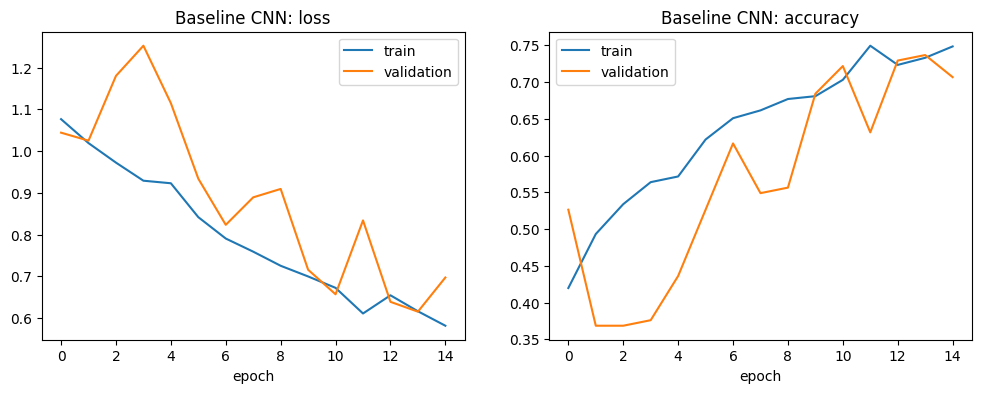

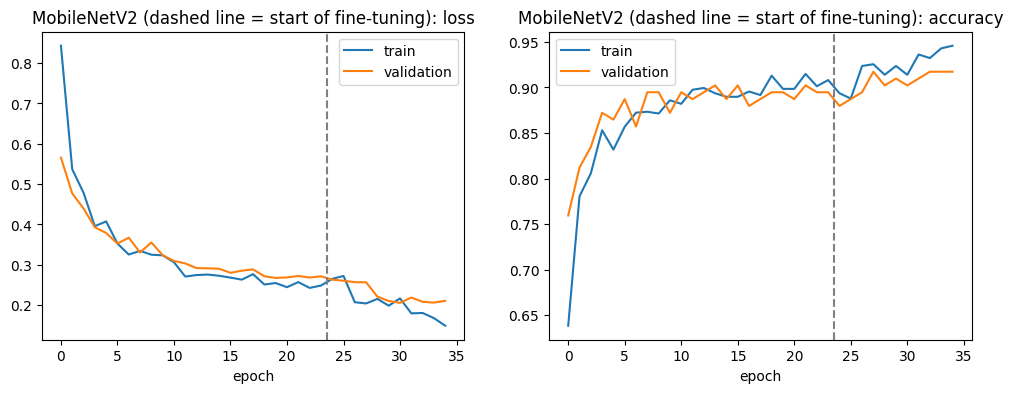

In [13]:
def curves(histories, title):
    h = {k: sum((hh.history[k] for hh in histories), []) for k in ["loss", "val_loss", "accuracy", "val_accuracy"]}
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="validation"); ax[0].set_title(title + ": loss")
    ax[1].plot(h["accuracy"], label="train"); ax[1].plot(h["val_accuracy"], label="validation"); ax[1].set_title(title + ": accuracy")
    if len(histories) > 1:
        for a in ax: a.axvline(len(histories[0].history["loss"]) - 0.5, ls="--", c="grey")
    for a in ax: a.legend(); a.set_xlabel("epoch")
    plt.show()
curves([hist_base], "Baseline CNN")
curves([hist1, hist2], "MobileNetV2 (dashed line = start of fine-tuning)")

## 6. Evaluation on the test set (pictures the model has never seen)
Metrics used:
- **Accuracy**: share of pictures classified correctly.
- **Loss** (cross-entropy): how confident and correct the probabilities are (lower is better).
- **Precision**: of the leaves the model *called* a class, how many really were that class.
- **Recall**: of the leaves that really *are* a class, how many the model found. For a farmer, missing a disease (low recall) is the costly mistake.
- **F1 score**: balance of precision and recall.
- **ROC-AUC**: how well the model ranks the right class above the others (1.0 is perfect).
- **Confusion matrix**: which classes get mixed up.

In [14]:
y_test = np.concatenate([y.numpy() for _, y in test_ds])

def evaluate(m):
    probs = m.predict(test_ds, verbose=0); preds = probs.argmax(1)
    return probs, preds, {
        "accuracy": round(accuracy_score(y_test, preds), 4),
        "loss": round(log_loss(y_test, probs, labels=[0, 1, 2]), 4),
        "precision": round(precision_score(y_test, preds, average="macro"), 4),
        "recall": round(recall_score(y_test, preds, average="macro"), 4),
        "f1": round(f1_score(y_test, preds, average="macro"), 4),
        "roc_auc": round(roc_auc_score(y_test, probs, multi_class="ovr"), 4),
    }

_, _, base_metrics = evaluate(baseline)
probs, preds, tl_metrics = evaluate(model)
comparison = pd.DataFrame({"Baseline CNN": base_metrics, "MobileNetV2 (optimised)": tl_metrics}).T
display(comparison)
print(classification_report(y_test, preds, target_names=CLASS_NAMES, digits=3))

,accuracy,loss,precision,recall,f1,roc_auc
Baseline CNN,0.7500,0.6197,0.7897,0.7514,0.7326,0.9089
MobileNetV2 (optimised),0.8906,0.2494,0.8959,0.8913,0.8890,0.9849


                   precision    recall  f1-score   support

angular_leaf_spot      0.820     0.953     0.882        43
        bean_rust      0.914     0.744     0.821        43
          healthy      0.953     0.976     0.965        42

         accuracy                          0.891       128
        macro avg      0.896     0.891     0.889       128
     weighted avg      0.895     0.891     0.888       128



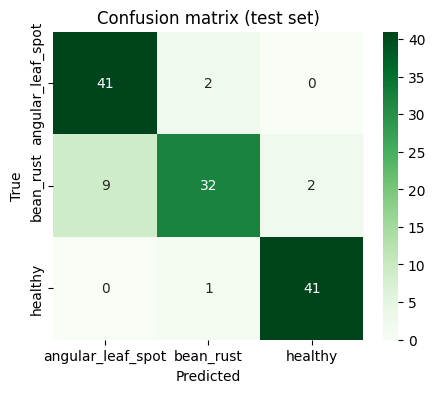

In [15]:
cm = confusion_matrix(y_test, preds)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix (test set)"); plt.show()

**Interpretation.**

| model | accuracy | loss | precision | recall | F1 | ROC-AUC |
|---|---|---|---|---|---|---|
| Baseline CNN (no optimisation) | 0.750 | 0.620 | 0.790 | 0.751 | 0.733 | 0.909 |
| MobileNetV2 (optimised) | **0.891** | **0.249** | **0.896** | **0.891** | **0.889** | **0.985** |

- Transfer learning beats the baseline on **every** metric: accuracy goes up by 14 points and the loss drops by more than half. The baseline had to learn what a leaf looks like from only about 1,000 photos. MobileNetV2 already knew edges and textures from ImageNet.
- **Healthy** leaves are recognised almost perfectly (F1 0.97). For a farmer this means few false alarms.
- The weakest number is **bean rust recall (0.74)**: about 1 in 4 rust leaves was labelled as angular leaf spot. This matches the feature analysis above: by colour, the two diseases look very similar. This mistake is less harmful than missing a disease completely, because the farmer is still told the leaf is sick.
- The learning curves show training and validation accuracy staying close together, so the model is **not overfitting**. Dropout, L2, augmentation and early stopping did their job.
- **Next improvements:** more photos of bean rust, higher-resolution input to see the tiny pustules, or fine-tuning more layers.

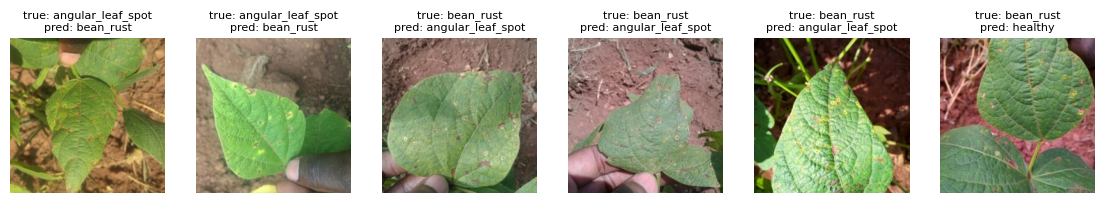

In [16]:
# look at some mistakes
test_files = sorted((DATA_DIR / "test").rglob("*.jpg"), key=lambda p: (CLASS_NAMES.index(p.parent.name), p.name))
wrong = [i for i in range(len(y_test)) if preds[i] != y_test[i]][:6]
plt.figure(figsize=(14, 3))
for k, i in enumerate(wrong):
    plt.subplot(1, 6, k + 1); plt.imshow(Image.open(test_files[i])); plt.axis("off")
    plt.title(f"true: {CLASS_NAMES[y_test[i]]}\npred: {CLASS_NAMES[preds[i]]}", fontsize=8)
plt.show()

## 7. Save the model
The model is saved as `models/bean_model.keras` (the format the API loads) and also as `.h5`, a format the brief accepts. The test metrics are saved to `models/metrics.json` so the website can show them.

In [17]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)
model.save(MODELS_DIR / "bean_model.keras")
try:
    model.save(MODELS_DIR / "bean_model.h5")   # extra copy in the older .h5 format
except Exception as e:
    print("Could not save .h5 (the .keras file is enough):", e)
cm_list = cm.tolist()
json.dump({"test": {**tl_metrics, "confusion_matrix": cm_list, "n_samples": int(len(y_test))},
           "baseline_test": base_metrics, "best_dropout": best_dropout,
           "tensorflow_version": tf.__version__, "retrain_count": 0},
          open(MODELS_DIR / "metrics.json", "w"), indent=2)
print(os.listdir(MODELS_DIR))

['bean_model.keras', 'metrics.json', 'bean_model.h5']


## 8. Prediction function
This is the same logic as `src/prediction.py`: load the saved model, preprocess one image, return the class and confidence.

In [18]:
loaded = keras.models.load_model(MODELS_DIR / "bean_model.keras")

def predict_image(path):
    img = Image.open(path).convert("RGB").resize(IMG_SIZE)
    x = np.expand_dims(np.asarray(img, dtype=np.float32), 0)
    p = loaded.predict(x, verbose=0)[0]
    return CLASS_NAMES[int(p.argmax())], float(p.max())

for cls in CLASS_NAMES:
    f = sorted((DATA_DIR / "test" / cls).glob("*.jpg"))[0]
    label, conf = predict_image(f)
    print(f"{f.name:30s} true={cls:18s} predicted={label:18s} confidence={conf:.2%}")

angular_leaf_spot_0000.jpg     true=angular_leaf_spot  predicted=angular_leaf_spot  confidence=92.71%
bean_rust_0043.jpg             true=bean_rust          predicted=bean_rust          confidence=99.91%
healthy_0086.jpg               true=healthy            predicted=healthy            confidence=99.11%


## 9. Retraining function (uses OUR saved model as the pre-trained model)
In the deployed app, new labelled pictures are uploaded, saved to the database and preprocessed. Retraining then:
1. **loads our saved bean model** (not a fresh MobileNetV2), so it builds on what it already learned,
2. trains it a few more epochs with a small learning rate on the new pictures **plus a sample of the old training pictures** (so it does not forget),
3. checks the test set before and after, and keeps the new model only if it is not worse.

Here we simulate it: we pretend 20 validation pictures are "new uploads".

**Result:** after retraining on 20 new pictures the test loss went down (0.249 → 0.236) and ROC-AUC went up (0.985 → 0.986), while accuracy moved by one image (0.891 → 0.883). The model kept what it knew and adjusted slightly to the new data. In the app, a new model is only kept if accuracy does not drop by more than 2 points.

In [19]:
def retrain(model_path, new_files, epochs=5):
    m = keras.models.load_model(model_path)
    before = evaluate(m)[2]
    replay = []
    for cls in CLASS_NAMES:
        old = sorted((DATA_DIR / "train" / cls).glob("*.jpg")); random.shuffle(old); replay += old[:60]
    files = list(new_files) + replay; random.shuffle(files)
    X = np.stack([np.asarray(Image.open(f).convert("RGB").resize(IMG_SIZE), dtype=np.float32) for f in files])
    y = np.array([CLASS_NAMES.index(Path(f).parent.name) for f in files])
    m.compile(optimizer=keras.optimizers.Adam(1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    m.fit(X, y, epochs=epochs, batch_size=16, validation_split=0.15, callbacks=callbacks(2), verbose=0)
    after = evaluate(m)[2]
    return m, before, after

new_uploads = sorted((PROJECT / "val_tmp").rglob("*.jpg")); random.shuffle(new_uploads)
_, before, after = retrain(MODELS_DIR / "bean_model.keras", new_uploads[:20])
pd.DataFrame({"before retraining": before, "after retraining": after}).T

,accuracy,loss,precision,recall,f1,roc_auc
before retraining,0.8906,0.2494,0.8959,0.8913,0.8890,0.9849
after retraining,0.8828,0.2360,0.8897,0.8835,0.8807,0.9861


## 10. Download the results
This zips `data/train`, `data/test` and `models/` so you can put them into the GitHub repository folders with the same names.

In [20]:
shutil.rmtree(PROJECT / "val_tmp", ignore_errors=True)
shutil.make_archive("bean-mlop-outputs", "zip", PROJECT)
try:
    from google.colab import files; files.download("bean-mlop-outputs.zip")
except ImportError:
    print("Saved bean-mlop-outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>